In [1]:
import pandas as pd
import numpy as np

import copepodTCR as cpp

# Figure 8: Fluorescent microscopy read out.

Percentage of GFP-producing (activated) cells in the T cell activation assay (y-axis) for each pool in the design (x-axis), with pools detected as activated/non-activated in green and grey, respectively. Results shown for the T cell reporter cell lines expressing DPB1*04:(01/02)-restricted TCR6.3 and HLA-A02+ restricted YLQ-TCR1 with their predicted cognate peptides indicated.

In [2]:
exp_data_m = pd.read_csv('./data/M_TCR6_YLQ_activation.tsv', sep = '\t')
cpp_scheme = pd.read_csv('./data/peptide-addresses_table.tsv', sep = '\t')
peptides = list(pd.read_csv('./data/peptides.tsv', sep = '\t', header = None)[0])

## pooling parameters
ep_length = 8
n_pools = 12
iters = 4

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 9 seconds.
/Users/kovaleva/miniforge3/envs/copepodTCR/lib/python3.10/site-packages/arviz/stats/diagnostics.py:596: RuntimeWarning: invalid value encountered in scalar divide
  (between_chain_variance / within_chain_variance + num_samples - 1) / (num_samples)
There were 96 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
Sampling: [lik, negative_obs]


Output()

Posterior mean of p: 0.584
No drop-outs were detected
Cognate peptides: ['SSANNCTFEYVSQPFLM', 'CTFEYVSQPFLMDLEGK']
Peptide candidates: ['SSANNCTFEYVSQPFLM', 'CTFEYVSQPFLMDLEGK']


<Axes: title={'center': 'SSANNCTFEYVSQPFLM or CTFEYVSQPFLMDLEGK'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

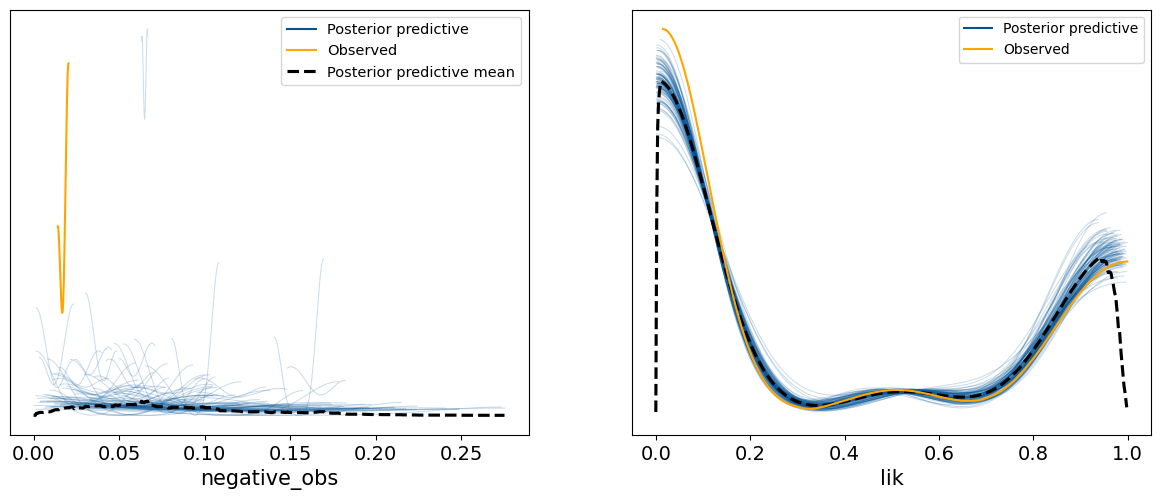

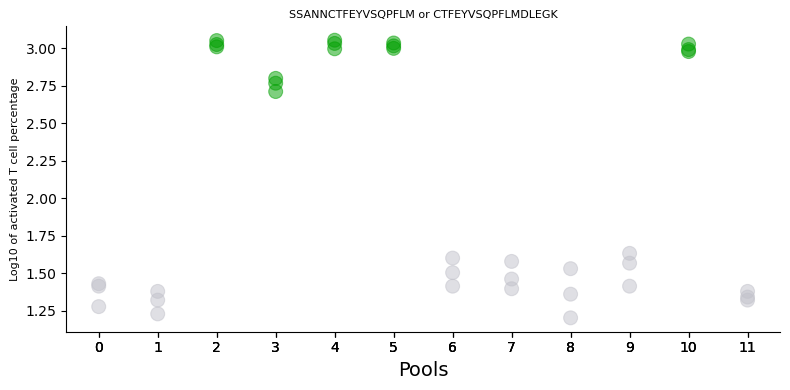

In [3]:
## TCR6_3

### preparing data for the model
obs = np.array(exp_data_m['TCR6_3_m(#)'][exp_data_m['type'] == 'pool'])
### pool indices
inds = np.array(exp_data_m['Pool'][exp_data_m['type'] == 'pool']).astype(int)
### negative control
neg_f1 = np.array(exp_data_m['TCR6_3_m(#)'][exp_data_m['Pool'] == 'unstim'])

### calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key = t.get)
neg_share = (n_pools - iters - e + 1) / n_pools

### fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_f1, neg_share=neg_share)
### calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
### decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

### Resulting plot
cpp.poolplot(probs, obs, inds, most)

Sequential sampling (2 chains in 1 job)
CompoundStep
>NUTS: [negative, offset_proportion, p, sigma_neg, sigm_pos, pool_dist, sigma_data]
>BinaryGibbsMetropolis: [assign]


Output()

Sampling 2 chains for 1_000 tune and 1_000 draw iterations (2_000 + 2_000 draws total) took 7 seconds.
There were 39 divergences after tuning. Increase `target_accept` or reparameterize.
We recommend running at least 4 chains for robust computation of convergence diagnostics
Sampling: [lik, negative_obs]


Output()

Posterior mean of p: 0.589
Drop-out was detected
Cognate peptides: ['YVGYLQPRTFLLKYNEN', 'GAAAYYVGYLQPRTFLL']
Peptide candidates: ['GAAAYYVGYLQPRTFLL', 'ATKMSECVLGQSKRVDF', 'YVGYLQPRTFLLKYNEN', 'SGWTAGAAAYYVGYLQP', 'KNLNESLIDLQELGKYE', 'SLIDLQELGKYEQYIKW', 'ECVLGQSKRVDFCGKGY']


<Axes: title={'center': 'YVGYLQPRTFLLKYNEN or GAAAYYVGYLQPRTFLL'}, xlabel='Pools', ylabel='Log10 of activated T cell percentage'>

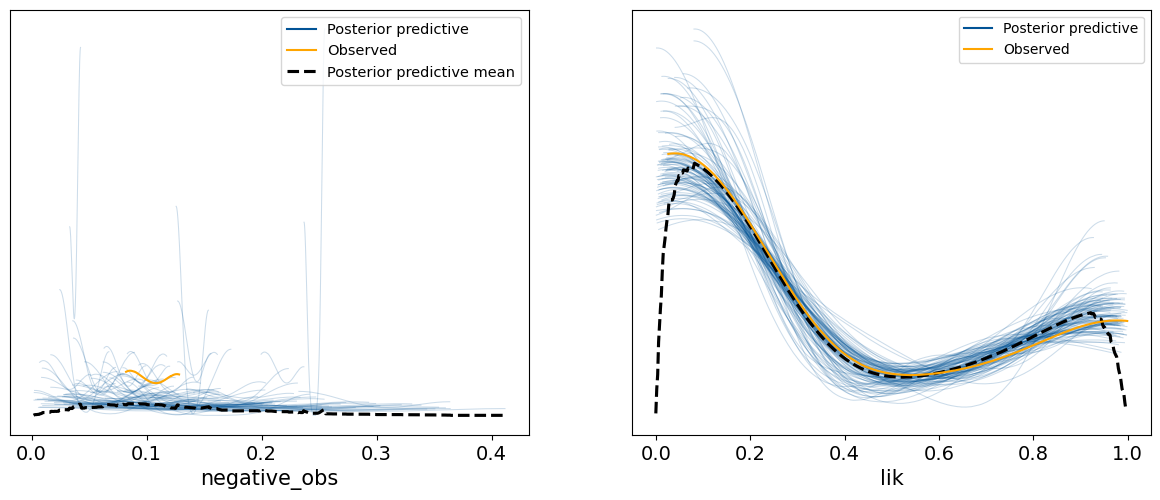

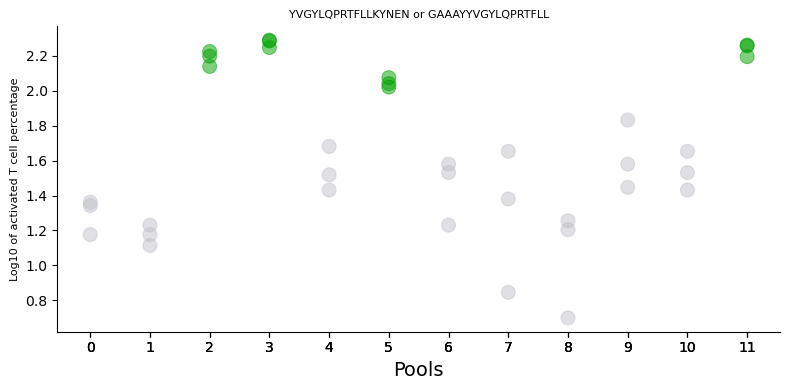

In [4]:
## YLQ_TCR1

### preparing data for the model
obs = np.array(exp_data_m['YLQ_TCR1_m(#)'][exp_data_m['type'] == 'pool'])
### pool indices
inds = np.array(exp_data_m['Pool'][exp_data_m['type'] == 'pool']).astype(int)
### negative control
neg_f2 = np.array(exp_data_m['YLQ_TCR1_m(#)'][exp_data_m['Pool'] == 'unstim'])

### calculating expected negative share
t, r = cpp.how_many_peptides(peptides, ep_length)
e = max(t, key = t.get)
neg_share = (n_pools - iters - e + 1) / n_pools

### fitting the model
model, fig, probs, n_c, pp, parameters = cpp.activation_model(obs, n_pools, inds, neg_f2, neg_share=neg_share)
### calculating peptide probabilities
peptide_probs = cpp.peptide_probabilities(cpp_scheme, probs)
### decision-tree algorithm
n_act_pools, message, most, possible = cpp.results_analysis(peptide_probs, probs, cpp_scheme)
print(message)
print(f'Cognate peptides: {most}')
print(f'Peptide candidates: {possible}')

### Resulting plot
cpp.poolplot(probs, obs, inds, most)